# Value Iteration Example

An implementation of Shapley's value iteration on the two-state Attacker/Defender game from the notes.

## Step 1: Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog

## Step 2: The game

A zero-sum game where Player 1 (Attacker) wants to maximize $r$ and Player 2 (Defender) wants to minimize $r$. There are two states, and transitions are deterministic. Each cell shows the reward $r(s,a)$ and the next state.

<table>
<tr>
<td>

<table>
<tr><th colspan="2" rowspan="2">s₁ (Secure)</th><th colspan="2">Player 2</th></tr>
<tr><th>Patch</th><th>Monitor</th></tr>
<tr><th rowspan="2">Player 1</th><th>Exploit</th><td>−2, stay in s₁</td><td>+3, go to s₂</td></tr>
<tr><th>Wait</th><td>+1, stay in s₁</td><td>−1, stay in s₁</td></tr>
</table>

</td>
<td width="80">&nbsp;</td>
<td>

<table>
<tr><th colspan="2" rowspan="2">s₂ (Infiltrated)</th><th colspan="2">Player 2</th></tr>
<tr><th>Reboot</th><th>Scan</th></tr>
<tr><th rowspan="2">Player 1</th><th>Exfiltrate</th><td>−1, go to s₁</td><td>+4, stay in s₂</td></tr>
<tr><th>Hide</th><td>+2, stay in s₂</td><td>−2, go to s₁</td></tr>
</table>

</td>
</tr>
</table>

In [2]:
# Reward matrix
R = [np.array([[-2.0, 3.0],
               [1.0, -1.0]]),
     np.array([[-1.0, 4.0],
               [2.0, -2.0]])]

# Next state
NEXT = [np.array([[0, 1],
                  [0, 0]]),
        np.array([[0, 1],
                  [1, 0]])]

n_states = len(R)
# Transition probability distribution
P = [np.eye(n_states)[NEXT[s]] for s in range(n_states)]

## Step 3: Value iteration

At each state, value iteration solves a matrix game whose payoffs are the reward now plus the discounted value of the state you end up in.

`solve_matrix_game` returns the value of the matrix game `Q` and each player's optimal mixed strategy (`x`, `y`) using linear programs.

In [3]:
def solve_matrix_game(Q):
    Q = np.asarray(Q, dtype=float)
    m, n = Q.shape
    # Player 1's optimal strategy
    res_x = linprog(c=np.r_[np.zeros(m), -1.0],
                    A_ub=np.c_[-Q.T, np.ones(n)], b_ub=np.zeros(n),
                    A_eq=np.r_[np.ones(m), 0.0][None, :], b_eq=[1.0],
                    bounds=[(0, None)] * m + [(None, None)], method="highs")
    # Player 2's optimal strategy
    res_y = linprog(c=np.r_[np.zeros(n), 1.0],
                    A_ub=np.c_[Q, -np.ones(m)], b_ub=np.zeros(m),
                    A_eq=np.r_[np.ones(n), 0.0][None, :], b_eq=[1.0],
                    bounds=[(0, None)] * n + [(None, None)], method="highs")
    # Checks that LP solver succeeded
    assert res_x.status == 0 and res_y.status == 0, "LP solver failed"
    x, y = np.clip(res_x.x[:m], 0, None), np.clip(res_y.x[:n], 0, None)
    return -res_x.fun, x / x.sum(), y / y.sum()

`local_game` builds the matrix game at state `s` from the current guess of the values `V`.

In [4]:
def local_game(V, s, gamma):
    return R[s] + gamma * P[s] @ V

`value_iteration_step` solves the matrix game at every state, giving a new guess and both players' strategies.

In [5]:
def value_iteration_step(V, gamma):
    W = np.empty(n_states)
    pi1, pi2 = [], []
    for s in range(n_states):
        W[s], x, y = solve_matrix_game(local_game(V, s, gamma))
        pi1.append(x)
        pi2.append(y)
    return W, pi1, pi2

`value_iteration` starts from `V = 0` and repeats `value_iteration_step` until the guess barely changes. It returns the values, both players' policies, and the residuals.

In [6]:
def value_iteration(gamma, eps, max_iters=100_000):
    V = np.zeros(n_states)
    residuals = []
    for _ in range(max_iters):
        W, pi1, pi2 = value_iteration_step(V, gamma)
        rho = np.max(np.abs(W - V))
        residuals.append(rho)
        if rho <= eps * (1 - gamma) / 2:
            return V, pi1, pi2, rho, residuals
        V = W
    raise RuntimeError("value iteration did not converge")

## Step 4: Residuals for different discount factors

The residual tells us how much an additional step of value iteration would change the values. We plot it for several discount factors $\gamma$, stopping each run at accuracy $\varepsilon = 10^{-6}$. The dashed lines show the upper bound from the notes (the residual is at most $\gamma^t R$, where $R = 4$ is the largest reward in absolute value).

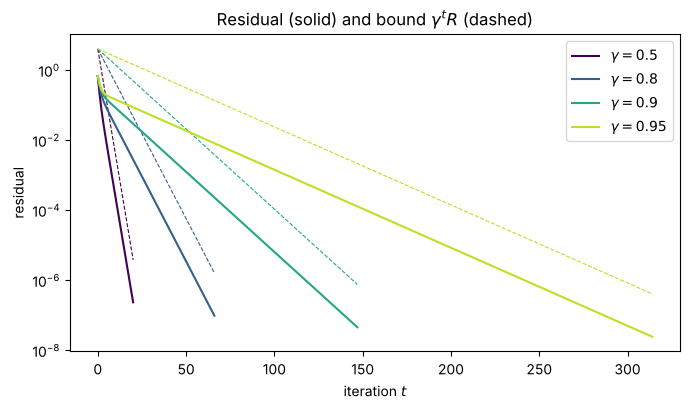

In [7]:
R_max = max(np.abs(r).max() for r in R)
gammas = [0.5, 0.8, 0.9, 0.95]
eps = 1e-6
runs = {}

fig, ax = plt.subplots(figsize=(7, 4.2))
for gamma, color in zip(gammas, plt.cm.viridis(np.linspace(0, 0.9, len(gammas)))):
    runs[gamma] = value_iteration(gamma, eps)
    V, pi1, pi2, rho, residuals = runs[gamma]
    t = np.arange(len(residuals))
    ax.semilogy(t, residuals, color=color, label=rf"$\gamma = {gamma}$")
    ax.semilogy(t, R_max * gamma ** t, color=color, ls="--", lw=0.8)
ax.set_xlabel("iteration $t$")
ax.set_ylabel("residual")
ax.set_title(r"Residual (solid) and bound $\gamma^t R$ (dashed)")
ax.legend()
plt.tight_layout()
plt.show()

## Step 5: Verifying the policies with best-response MDPs

To check the returned policies, we freeze one player's policy. The other player then faces an ordinary MDP, which we can solve exactly. If neither player can do noticeably better than the returned policies, they form an approximate equilibrium.

`evaluate` computes Player 1's expected total reward from each state when both players follow the given policies.

In [8]:
def evaluate(pi1, pi2, gamma):
    r_pi = np.array([pi1[s] @ R[s] @ pi2[s] for s in range(n_states)])
    Gamma = np.array([np.einsum("i,j,ijk->k", pi1[s], pi2[s], P[s]) for s in range(n_states)])
    return np.linalg.solve(np.eye(n_states) - gamma * Gamma, r_pi)

`solve_mdp` finds the best possible value in each state of an MDP using policy iteration.

In [9]:
def solve_mdp(r, P, gamma):
    policy = np.zeros(n_states, dtype=int)
    while True:
        r_pol = np.array([r[s][policy[s]] for s in range(n_states)])
        P_pol = np.array([P[s][policy[s]] for s in range(n_states)])
        v = np.linalg.solve(np.eye(n_states) - gamma * P_pol, r_pol)
        q = [r[s] + gamma * P[s] @ v for s in range(n_states)]
        if all(q[s].max() <= v[s] + 1e-12 for s in range(n_states)):
            return v
        policy = np.array([np.argmax(q[s]) for s in range(n_states)])

`best_response_value` freezes the other player's policy and averages out their actions to create an MDP for `player`. It then solves the MDP and returns the best value.

In [10]:
def best_response_value(player, pi_other, gamma):
    if player == 1:
        r = [R[s] @ pi_other[s] for s in range(n_states)]
        P_mdp = [np.einsum("ijk,j->ik", P[s], pi_other[s]) for s in range(n_states)]
        return solve_mdp(r, P_mdp, gamma)
    else:
        r = [-(pi_other[s] @ R[s]) for s in range(n_states)]
        P_mdp = [np.einsum("i,ijk->jk", pi_other[s], P[s]) for s in range(n_states)]
        return -solve_mdp(r, P_mdp, gamma)

`deviation_gains` returns how much each player could gain by switching from the returned policy to their best response. This tells us how close the policies are to an equilibrium.

In [11]:
def deviation_gains(pi1, pi2, gamma):
    v = evaluate(pi1, pi2, gamma)
    gain1 = best_response_value(1, pi2, gamma) - v
    gain2 = v - best_response_value(2, pi1, gamma)
    return gain1, gain2

Finally, for each discount factor from Step 4, we compute each player's largest possible gain and compare it with the bound $2\rho/(1-\gamma)$ from the notes.

In [12]:
print(f"{'gamma':>6} {'max gain P1':>12} {'max gain P2':>12} {'bound 2rho/(1-gamma)':>21}")
for gamma in gammas:
    V, pi1, pi2, rho, residuals = runs[gamma]
    gain1, gain2 = deviation_gains(pi1, pi2, gamma)
    gain1, gain2 = np.maximum(gain1, 0), np.maximum(gain2, 0)     # hide rounding noise around 1e-15
    bound = 2 * rho / (1 - gamma)
    assert max(gain1.max(), gain2.max()) <= bound + 1e-9          # the guarantee from the notes holds
    print(f"{gamma:>6} {gain1.max():>12.2e} {gain2.max():>12.2e} {bound:>21.2e}")

 gamma  max gain P1  max gain P2  bound 2rho/(1-gamma)
   0.5     1.61e-15     1.17e-15              9.31e-07
   0.8     0.00e+00     6.66e-16              9.68e-07
   0.9     0.00e+00     2.22e-15              9.01e-07
  0.95     2.66e-15     2.66e-15              9.69e-07


In every case, neither player can gain more than the bound. Since value iteration stops once $\rho \le \varepsilon(1-\gamma)/2$, the bound is at most $\varepsilon = 10^{-6}$. So the returned policies form a $10^{-6}$-approximate equilibrium (no player can improve by more than $10^{-6}$ by deviating).